In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[2])

In [3]:
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [4]:
%matplotlib inline

In [5]:
path = "./demo_movie_mcorr.tiff"
movie = tifffile.imread(path)

In [6]:
unvec = UnVectorizer(movie.shape[1:])

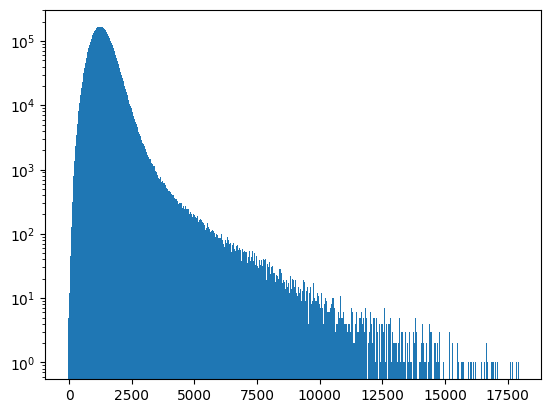

In [7]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [8]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [9]:
sn, psdx = get_noise_fft(movie.transpose(1, 2, 0))

movie /= sn

In [10]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

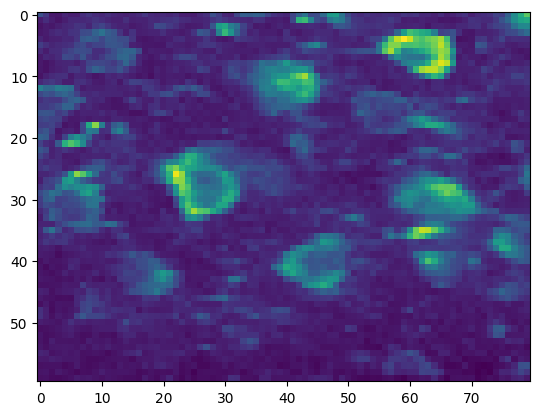

In [11]:
plt.imshow(movie.max(axis=0))

In [12]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [13]:
filt_movie = PercentileFilter(window_size=5, quantile=5).transform(movie)

In [14]:
iw_movie.set_data(unvec.transform(filt_movie), reset_indices=False)

In [15]:
Y = filt_movie
Y

array([[3.9555044, 3.9555044, 3.979043 , ..., 5.2926354, 7.0192747,
        0.       ],
       [2.8230271, 2.8230271, 2.6630697, ..., 5.0753803, 7.4273214,
        0.       ],
       [4.04362  , 3.877677 , 3.816458 , ..., 7.121609 , 9.414356 ,
        0.       ],
       ...,
       [3.0948222, 3.0948222, 3.1786983, ..., 7.175075 , 7.712297 ,
        0.       ],
       [2.8276913, 2.8276913, 2.8276913, ..., 7.565169 , 8.054787 ,
        0.       ],
       [2.8435502, 2.8435502, 3.4438426, ..., 5.297539 , 7.0595865,
        0.       ]], dtype=float32)

In [16]:
Y.shape

(4800, 2000)

In [20]:
ixs = np.where(np.apply_along_axis(lambda Y_p: np.count_nonzero(Y_p > 3.0) > 10, axis=1, arr=Y))[0]

In [18]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [20]:
@njit(parallel=True)
def get_distances(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dists: np.ndarray,
    # low_dists_h: np.ndarray,
    # low_dists_v: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        # u = u**2
        # v = v**2

        # X = np.column_stack([u, v])
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        # projections = (X @ Vt[0, :])[:, None] * Vt[0, :]
        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        dists[j] = s

        # # hline and vline distances
        # hline = np.array([1., 0.])
        # vline = np.array([0., 1.])

        # projections_h_pre = (X @ hline)
        # projections_v_pre = (X @ vline)

        # projections_h = np.zeros((u.size, 2))
        # projections_h[:, 0] = projections_h_pre * hline[0]
        
        # projections_v = np.zeros((u.size, 2))
        # projections_v[:, 1] = projections_v_pre * vline[1]

        # odists_h = np.abs(X - projections_h)
        # low_dists_h[j] = np.count_nonzero(odists_h < orthogonal_distances) / orthogonal_distances.size

        # odists_v = np.abs(X - projections_v)
        # low_dists_v[j] = np.count_nonzero(odists_v < orthogonal_distances) / orthogonal_distances.size

In [21]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))
# output_h = np.zeros((Y.shape[0],))
# output_v = np.zeros((Y.shape[0],))

In [22]:
projections.shape

(4800, 2000, 2)

In [52]:
get_distances(
    2343,
    Y,
    projections,
    output_matrix,
    # output_h,
    # output_v
)

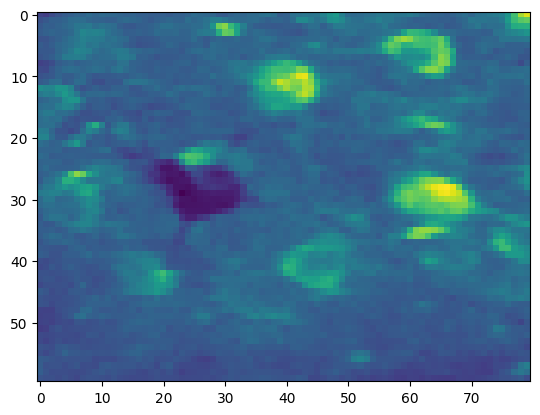

In [53]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis")

In [54]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [55]:
for i in tqdm(range(Y.shape[0])):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    output_h = np.zeros((Y.shape[0],))
    output_v = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        projections,
        output_matrix,
        # output_h,
        # output_v,
    )
    dist_cov[i] = output_matrix

100%|█████████████████████████████████████████████████████████████████████| 4800/4800 [02:05<00:00, 38.23it/s]


In [57]:
dist_cov

array([[2.58348410e-13, 1.11222664e+02, 2.62766602e+02, ...,
        4.42629761e+02, 4.41444702e+02, 3.69042542e+02],
       [1.11222664e+02, 3.86749064e-13, 1.48056580e+02, ...,
        3.81924988e+02, 3.66607605e+02, 3.05692993e+02],
       [2.62766602e+02, 1.48056580e+02, 2.51070323e-13, ...,
        3.03672516e+02, 3.14866425e+02, 2.69572876e+02],
       ...,
       [4.42629761e+02, 3.81924988e+02, 3.03672516e+02, ...,
        1.74594280e-13, 1.01836090e+02, 1.76006607e+02],
       [4.41444702e+02, 3.66607605e+02, 3.14866425e+02, ...,
        1.01836090e+02, 1.07722072e-13, 1.16645988e+02],
       [3.69042542e+02, 3.05692993e+02, 2.69572876e+02, ...,
        1.76006607e+02, 1.16645988e+02, 1.71549678e-13]], dtype=float32)

In [58]:
dist_cov.min(), dist_cov.max()

(np.float32(5.964727e-14), np.float32(3440.091))

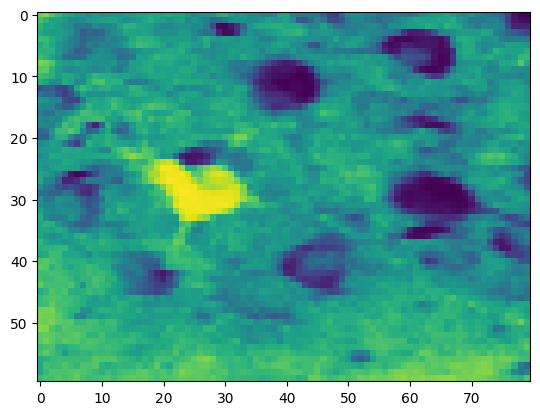

In [123]:
B = np.exp(-dist_cov**2 / 10e2**2)
plt.imshow(unvec.transform(B[2343]), cmap="viridis")

In [124]:
B.min(), B.max()

(np.float32(7.252048e-06), np.float32(1.0))

In [125]:
import numpy as np
import scipy.optimize as opt
import scipy.sparse as sps
import numpy.linalg as nla
import scipy.linalg as sla
import time


def nnlsm_blockpivot(A, B, is_input_prod=False, init=None):
    """ Nonnegativity-constrained least squares with block principal pivoting method and column grouping

    Solves min ||AX-B||_2^2 s.t. X >= 0 element-wise.

    J. Kim and H. Park, Fast nonnegative matrix factorization: An active-set-like method and comparisons,
    SIAM Journal on Scientific Computing,
    vol. 33, no. 6, pp. 3261-3281, 2011.

    Parameters
    ----------
    A : numpy.array, shape (m,n)
    B : numpy.array or scipy.sparse matrix, shape (m,k)

    Optional Parameters
    -------------------
    is_input_prod : True/False. -  If True, the A and B arguments are interpreted as
            AtA and AtB, respectively. Default is False.
    init: numpy.array, shape (n,k). - If provided, init is used as an initial value for the algorithm.
            Default is None.

    Returns
    -------
    X, (success, Y, num_cholesky, num_eq, num_backup)
    X : numpy.array, shape (n,k) - solution
    success : True/False - True if the solution is found. False if the algorithm did not terminate
            due to numerical errors.
    Y : numpy.array, shape (n,k) - Y = A.T * A * X - A.T * B
    num_cholesky : int - the number of Cholesky factorizations needed
    num_eq : int - the number of linear systems of equations needed to be solved
    num_backup: int - the number of appearances of the back-up rule. See SISC paper for details.
    """
    if is_input_prod:
        AtA = A
        AtB = B
    else:
        AtA = A.T.dot(A)
        if sps.issparse(B):
            AtB = B.T.dot(A)
            AtB = AtB.T
        else:
            AtB = A.T.dot(B)

    (n, k) = AtB.shape
    MAX_ITER = n * 5

    if init is not  None:
        PassSet = init > 0
        X, num_cholesky, num_eq = normal_eq_comb(AtA, AtB, PassSet)
        Y = AtA.dot(X) - AtB
    else:
        X = np.zeros([n, k])
        Y = -AtB
        PassSet = np.zeros([n, k], dtype=bool)
        num_cholesky = 0
        num_eq = 0

    p_bar = 3
    p_vec = np.zeros([k])
    p_vec[:] = p_bar
    ninf_vec = np.zeros([k])
    ninf_vec[:] = n + 1
    not_opt_set = np.logical_and(Y < 0, ~PassSet)
    infea_set = np.logical_and(X < 0, PassSet)

    not_good = np.sum(not_opt_set, axis=0) + np.sum(infea_set, axis=0)
    not_opt_colset = not_good > 0
    not_opt_cols = not_opt_colset.nonzero()[0]

    big_iter = 0
    num_backup = 0
    success = True
    while not_opt_cols.size > 0:
        big_iter += 1
        if MAX_ITER > 0 and big_iter > MAX_ITER:
            success = False
            break

        cols_set1 = np.logical_and(not_opt_colset, not_good < ninf_vec)
        temp1 = np.logical_and(not_opt_colset, not_good >= ninf_vec)
        temp2 = p_vec >= 1
        cols_set2 = np.logical_and(temp1, temp2)
        cols_set3 = np.logical_and(temp1, ~temp2)

        cols1 = cols_set1.nonzero()[0]
        cols2 = cols_set2.nonzero()[0]
        cols3 = cols_set3.nonzero()[0]

        if cols1.size > 0:
            p_vec[cols1] = p_bar
            ninf_vec[cols1] = not_good[cols1]
            true_set = np.logical_and(not_opt_set, np.tile(cols_set1, (n, 1)))
            false_set = np.logical_and(infea_set, np.tile(cols_set1, (n, 1)))
            PassSet[true_set] = True
            PassSet[false_set] = False
        if cols2.size > 0:
            p_vec[cols2] = p_vec[cols2] - 1
            temp_tile = np.tile(cols_set2, (n, 1))
            true_set = np.logical_and(not_opt_set, temp_tile)
            false_set = np.logical_and(infea_set, temp_tile)
            PassSet[true_set] = True
            PassSet[false_set] = False
        if cols3.size > 0:
            for col in cols3:
                candi_set = np.logical_or(
                    not_opt_set[:, col], infea_set[:, col])
                to_change = np.max(candi_set.nonzero()[0])
                PassSet[to_change, col] = ~PassSet[to_change, col]
                num_backup += 1

        (X[:, not_opt_cols], temp_cholesky, temp_eq) = normal_eq_comb(
            AtA, AtB[:, not_opt_cols], PassSet[:, not_opt_cols])
        num_cholesky += temp_cholesky
        num_eq += temp_eq
        X[abs(X) < 1e-12] = 0
        Y[:, not_opt_cols] = AtA.dot(X[:, not_opt_cols]) - AtB[:, not_opt_cols]
        Y[abs(Y) < 1e-12] = 0

        not_opt_mask = np.tile(not_opt_colset, (n, 1))
        not_opt_set = np.logical_and(
            np.logical_and(not_opt_mask, Y < 0), ~PassSet)
        infea_set = np.logical_and(
            np.logical_and(not_opt_mask, X < 0), PassSet)
        not_good = np.sum(not_opt_set, axis=0) + np.sum(infea_set, axis=0)
        not_opt_colset = not_good > 0
        not_opt_cols = not_opt_colset.nonzero()[0]

    return X, (success, Y, num_cholesky, num_eq, num_backup)


def nnlsm_activeset(A, B, overwrite=False, is_input_prod=False, init=None):
    """ Nonnegativity-constrained least squares with active-set method and column grouping

    Solves min ||AX-B||_2^2 s.t. X >= 0 element-wise.

    Algorithm of this routine is close to the one presented in the following paper but
    is different in organising inner- and outer-loops:
    M. H. Van Benthem and M. R. Keenan, J. Chemometrics 2004; 18: 441-450

    Parameters
    ----------
    A : numpy.array, shape (m,n)
    B : numpy.array or scipy.sparse matrix, shape (m,k)

    Optional Parameters
    -------------------
    is_input_prod : True/False. -  If True, the A and B arguments are interpreted as
            AtA and AtB, respectively. Default is False.
    init: numpy.array, shape (n,k). - If provided, init is used as an initial value for the algorithm.
            Default is None.

    Returns
    -------
    X, (success, Y, num_cholesky, num_eq, num_backup)
    X : numpy.array, shape (n,k) - solution
    success : True/False - True if the solution is found. False if the algorithm did not terminate
            due to numerical errors.
    Y : numpy.array, shape (n,k) - Y = A.T * A * X - A.T * B
    num_cholesky : int - the number of Cholesky factorizations needed
    num_eq : int - the number of linear systems of equations needed to be solved
    """
    if is_input_prod:
        AtA = A
        AtB = B
    else:
        AtA = A.T.dot(A)
        if sps.issparse(B):
            AtB = B.T.dot(A)
            AtB = AtB.T
        else:
            AtB = A.T.dot(B)

    (n, k) = AtB.shape
    MAX_ITER = n * 5
    num_cholesky = 0
    num_eq = 0
    not_opt_set = np.ones([k], dtype=bool)

    if overwrite:
        X, num_cholesky, num_eq = normal_eq_comb(AtA, AtB)
        PassSet = X > 0
        not_opt_set = np.any(X < 0, axis=0)
    elif init is not None:
        X = init
        X[X < 0] = 0
        PassSet = X > 0
    else:
        X = np.zeros([n, k])
        PassSet = np.zeros([n, k], dtype=bool)

    Y = np.zeros([n, k])
    opt_cols = (~not_opt_set).nonzero()[0]
    not_opt_cols = not_opt_set.nonzero()[0]

    Y[:, opt_cols] = AtA.dot(X[:, opt_cols]) - AtB[:, opt_cols]

    big_iter = 0
    success = True
    while not_opt_cols.size > 0:
        big_iter += 1
        if MAX_ITER > 0 and big_iter > MAX_ITER:
            success = False
            break

        (Z, temp_cholesky, temp_eq) = normal_eq_comb(
            AtA, AtB[:, not_opt_cols], PassSet[:, not_opt_cols])
        num_cholesky += temp_cholesky
        num_eq += temp_eq

        Z[abs(Z) < 1e-12] = 0

        infea_subset = Z < 0
        temp = np.any(infea_subset, axis=0)
        infea_subcols = temp.nonzero()[0]
        fea_subcols = (~temp).nonzero()[0]

        if infea_subcols.size > 0:
            infea_cols = not_opt_cols[infea_subcols]

            (ix0, ix1_subsub) = infea_subset[:, infea_subcols].nonzero()
            ix1_sub = infea_subcols[ix1_subsub]
            ix1 = not_opt_cols[ix1_sub]

            X_infea = X[(ix0, ix1)]

            alpha = np.zeros([n, len(infea_subcols)])
            alpha[:] = np.inf
            alpha[(ix0, ix1_subsub)] = X_infea / (X_infea - Z[(ix0, ix1_sub)])
            min_ix = np.argmin(alpha, axis=0)
            min_vals = alpha[(min_ix, range(0, alpha.shape[1]))]

            X[:, infea_cols] = X[:, infea_cols] + \
                (Z[:, infea_subcols] - X[:, infea_cols]) * min_vals
            X[(min_ix, infea_cols)] = 0
            PassSet[(min_ix, infea_cols)] = False

        elif fea_subcols.size > 0:
            fea_cols = not_opt_cols[fea_subcols]

            X[:, fea_cols] = Z[:, fea_subcols]
            Y[:, fea_cols] = AtA.dot(X[:, fea_cols]) - AtB[:, fea_cols]

            Y[abs(Y) < 1e-12] = 0

            not_opt_subset = np.logical_and(
                Y[:, fea_cols] < 0, ~PassSet[:, fea_cols])
            new_opt_cols = fea_cols[np.all(~not_opt_subset, axis=0)]
            update_cols = fea_cols[np.any(not_opt_subset, axis=0)]

            if update_cols.size > 0:
                val = Y[:, update_cols] * ~PassSet[:, update_cols]
                min_ix = np.argmin(val, axis=0)
                PassSet[(min_ix, update_cols)] = True

            not_opt_set[new_opt_cols] = False
            not_opt_cols = not_opt_set.nonzero()[0]

    return X, (success, Y, num_cholesky, num_eq)


def normal_eq_comb(AtA, AtB, PassSet=None):
    """ Solve many systems of linear equations using combinatorial grouping.

    M. H. Van Benthem and M. R. Keenan, J. Chemometrics 2004; 18: 441-450

    Parameters
    ----------
    AtA : numpy.array, shape (n,n)
    AtB : numpy.array, shape (n,k)

    Returns
    -------
    (Z,num_cholesky,num_eq)
    Z : numpy.array, shape (n,k) - solution
    num_cholesky : int - the number of unique cholesky decompositions done
    num_eq: int - the number of systems of linear equations solved
    """
    num_cholesky = 0
    num_eq = 0
    if AtB.size == 0:
        Z = np.zeros([])
    elif (PassSet is None) or np.all(PassSet):
        Z = nla.solve(AtA, AtB)
        num_cholesky = 1
        num_eq = AtB.shape[1]
    else:
        Z = np.zeros(AtB.shape)
        if PassSet.shape[1] == 1:
            if np.any(PassSet):
                cols = PassSet.nonzero()[0]
                Z[cols] = nla.solve(AtA[np.ix_(cols, cols)], AtB[cols])
                num_cholesky = 1
                num_eq = 1
        else:
            #
            # Both _column_group_loop() and _column_group_recursive() work well.
            # Based on preliminary testing,
            # _column_group_loop() is slightly faster for tiny k(<10), but
            # _column_group_recursive() is faster for large k's.
            #
            grps = _column_group_recursive(PassSet)
            for gr in grps:
                cols = PassSet[:, gr[0]].nonzero()[0]
                if cols.size > 0:
                    ix1 = np.ix_(cols, gr)
                    ix2 = np.ix_(cols, cols)
                    #
                    # scipy.linalg.cho_solve can be used instead of numpy.linalg.solve.
                    # For small n(<200), numpy.linalg.solve appears faster, whereas
                    # for large n(>500), scipy.linalg.cho_solve appears faster.
                    # Usage example of scipy.linalg.cho_solve:
                    # Z[ix1] = sla.cho_solve(sla.cho_factor(AtA[ix2]),AtB[ix1])
                    #
                    Z[ix1] = nla.solve(AtA[ix2], AtB[ix1])
                    num_cholesky += 1
                    num_eq += len(gr)
                    num_eq += len(gr)
    return Z, num_cholesky, num_eq


def _column_group_loop(B):
    """ Given a binary matrix, find groups of the same columns
        with a looping strategy

    Parameters
    ----------
    B : numpy.array, True/False in each element

    Returns
    -------
    A list of arrays - each array contain indices of columns that are the same.
    """
    initial = [np.arange(0, B.shape[1])]
    before = initial
    after = []
    for i in range(0, B.shape[0]):
        all_ones = True
        vec = B[i]
        for cols in before:
            if len(cols) == 1:
                after.append(cols)
            else:
                all_ones = False
                subvec = vec[cols]
                trues = subvec.nonzero()[0]
                falses = (~subvec).nonzero()[0]
                if trues.size > 0:
                    after.append(cols[trues])
                if falses.size > 0:
                    after.append(cols[falses])
        before = after
        after = []
        if all_ones:
            break
    return before


def _column_group_recursive(B):
    """ Given a binary matrix, find groups of the same columns
        with a recursive strategy

    Parameters
    ----------
    B : numpy.array, True/False in each element

    Returns
    -------
    A list of arrays - each array contain indices of columns that are the same.
    """
    initial = np.arange(0, B.shape[1])
    return [a for a in column_group_sub(B, 0, initial) if len(a) > 0]


def column_group_sub(B, i, cols):
    vec = B[i][cols]
    if len(cols) <= 1:
        return [cols]
    if i == (B.shape[0] - 1):
        col_trues = cols[vec.nonzero()[0]]
        col_falses = cols[(~vec).nonzero()[0]]
        return [col_trues, col_falses]
    else:
        col_trues = cols[vec.nonzero()[0]]
        col_falses = cols[(~vec).nonzero()[0]]
        after = column_group_sub(B, i + 1, col_trues)
        after.extend(column_group_sub(B, i + 1, col_falses))
    return after


def _test_column_grouping(m=10, n=5000, num_repeat=5, verbose=False):
    print ('\nTesting column_grouping ...\n')
    A = np.array([[True, False, False, False, False],
                  [True, True, False, True, True]])
    grps1 = _column_group_loop(A)
    grps2 = _column_group_recursive(A)
    grps3 = [np.array([0]),
             np.array([1, 3, 4]),
             np.array([2])]
    print ('OK' if all([np.array_equal(a, b) for (a, b) in zip(grps1, grps2)]) else 'Fail')
    print ('OK' if all([np.array_equal(a, b) for (a, b) in zip(grps1, grps3)]) else 'Fail')

    for i in iter(range(0, num_repeat)):
        A = np.random.rand(m, n)
        B = A > 0.5
        start = time.time()
        grps1 = _column_group_loop(B)
        elapsed_loop = time.time() - start
        start = time.time()
        grps2 = _column_group_recursive(B)
        elapsed_recursive = time.time() - start
        if verbose:
            print ('Loop     :', elapsed_loop)
            print ('Recursive:', elapsed_recursive)
        print ('OK' if all([np.array_equal(a, b) for (a, b) in zip(grps1, grps2)]) else 'Fail')
    # sorted_idx = np.concatenate(grps)
    # print B
    # print sorted_idx
    # print B[:,sorted_idx]
    return


def _test_normal_eq_comb(m=10, k=3, num_repeat=5):
    print ('\nTesting normal_eq_comb() ...\n')
    for i in iter(range(0, num_repeat)):
        A = np.random.rand(2 * m, m)
        X = np.random.rand(m, k)
        C = (np.random.rand(m, k) > 0.5)
        X[~C] = 0
        B = A.dot(X)
        B = A.T.dot(B)
        A = A.T.dot(A)
        Sol, a, b = normal_eq_comb(A, B, C)
        print ('OK' if np.allclose(X, Sol) else 'Fail')
    return


def _test_nnlsm():
    print ('\nTesting nnls routines ...\n')
    m = 100
    n = 10
    k = 200
    rep = 5

    for r in iter(range(0, rep)):
        A = np.random.rand(m, n)
        X_org = np.random.rand(n, k)
        X_org[np.random.rand(n, k) < 0.5] = 0
        B = A.dot(X_org)
        # B = np.random.rand(m,k)
        # A = np.random.rand(m,n/2)
        # A = np.concatenate((A,A),axis=1)
        # A = A + np.random.rand(m,n)*0.01
        # B = np.random.rand(m,k)

        import time
        start = time.time()
        C1, info = nnlsm_blockpivot(A, B)
        elapsed2 = time.time() - start
        rel_norm2 = nla.norm(C1 - X_org) / nla.norm(X_org)
        print ('nnlsm_blockpivot:    ', 'OK  ' if info[0] else 'Fail',\
            'elapsed:{0:.4f} error:{1:.4e}'.format(elapsed2, rel_norm2))

        start = time.time()
        C2, info = nnlsm_activeset(A, B)
        num_backup = 0
        elapsed1 = time.time() - start
        rel_norm1 = nla.norm(C2 - X_org) / nla.norm(X_org)
        print ('nnlsm_activeset:     ', 'OK  ' if info[0] else 'Fail',\
            'elapsed:{0:.4f} error:{1:.4e}'.format(elapsed1, rel_norm1))

        start = time.time()
        C3 = np.zeros([n, k])
        for i in iter(range(0, k)):
            res = opt.nnls(A, B[:, i])
            C3[:, i] = res[0]
        elapsed3 = time.time() - start
        rel_norm3 = nla.norm(C3 - X_org) / nla.norm(X_org)
        print ('scipy.optimize.nnls: ', 'OK  ',\
            'elapsed:{0:.4f} error:{1:.4e}'.format(elapsed3, rel_norm3))

        if num_backup > 0:
            break
        if rel_norm1 > 10e-5 or rel_norm2 > 10e-5 or rel_norm3 > 10e-5:
            break
        print ('')

In [126]:
import numpy as np
from tqdm import tqdm


class SymNMF:
    def __init__(
            self,
            A: np.ndarray,
            k: int,
            H: np.ndarray = None,
            maxiter: int = 10_000,
            tol: float = 10e-3,
            alpha: float = None,
    ):
        self.A = A

        if H is None:
            self.H = 2 * np.sqrt(np.mean(np.mean(A) / k)) * np.random.rand(self.A.shape[0], k)

        else:
            self.H = H

        if self.H.shape[0] != A.shape[0]:
            raise ValueError

        if alpha is None:
            self.alpha = np.max(A) ** 2
        else:
            self.alpha = alpha

        self.maxiter = maxiter
        self.tol = tol
        self.k = k

    def fit(self):
        self.W = self.H
        self.I_k = self.alpha * np.eye(self.k)

        self.left = self.H.conj().T @ self.H
        self.right = self.A @ self.H

        for self.i in tqdm(range(self.maxiter)):
            self.W = nnlsm_blockpivot(
                self.left + self.I_k,
                (self.right + self.alpha * self.H).conj().T,
                True,
                self.W.conj().T
            )[0].T

            self.left = self.W.conj().T @ self.W
            self.right = self.A @ self.W

            self.H = nnlsm_blockpivot(
                self.left + self.I_k,
                (self.right + self.alpha * self.W).conj().T,
                True,
                self.H.conj().T
            )[0].T
            # tempW = W.sum(axis=1)
            # tempH = H.sum(axis=1)

            temp = self.alpha * (self.H - self.W)

            gradH = self.H @ self.left - self.right + temp
            self.left = self.H.conj().T @ self.H
            self.right = self.A @ self.H

            gradW = self.W @ self.left - self.right - temp

            W_norm = np.linalg.norm(gradW[(gradW <= 0) | (self.W > 0)])
            H_norm = np.linalg.norm(gradH[(gradH <= 0) | (self.H > 0)])

            if self.i == 0:
                initgrad = np.sqrt(W_norm ** 2 + H_norm ** 2)
            else:
                projnorm = np.sqrt(W_norm ** 2 + H_norm ** 2)
                if projnorm < self.tol * initgrad:
                    break

In [128]:
B.dtype

dtype('float32')

In [137]:
snmf = SymNMF(B, k=20)

In [138]:
snmf.fit()

  0%|▏                                                                     | 20/10000 [00:05<44:00,  3.78it/s]


RFBOutputContext()

JupyterWgpuCanvas()
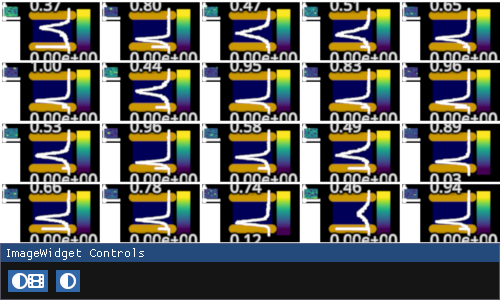

In [140]:
iw_s = fpl.ImageWidget([a for a in unvec.transform(snmf.W)], cmap="viridis")
iw_s.show()

In [141]:
for g in iw_s.managed_graphics:
    g.vmin = np.percentile(g.data[:], 70)